# Phase 1 · Preliminary training

Trains three of the six architectures of the project brief (Logistic Regression, Naive Bayes and Decision Tree) on the pixel samples extracted by the `extract_training_samples` DAG, and reports the confusion matrix and the overall accuracy of each one.

- **Dataset**: `s3://<DATA_BUCKET>/tsv/<DATASET>.tsv` (`Latitude`, `Longitude`, the ten bands, `Class`).
- **Split**: by polygon. The pixels of one polygon are nearly identical, so a polygon is never shared between train and test; otherwise the accuracy would be inflated.
- **Hyper-parameters**: library defaults. Tuning belongs to phase 2.
- **Outputs**: one MLflow run per model, and the figures and tables of the report under `outputs/phase1/`.

In [1]:
import io
import json
import os
from pathlib import Path

import boto3
import matplotlib.pyplot as plt
import mlflow
import pandas as pd
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, cohen_kappa_score, confusion_matrix, f1_score,
)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sqlalchemy import URL, create_engine, text

DATASET = "T18NWL_20260810T152649"
BANDS = [band.strip() for band in os.environ["BAND_NAMES"].split(",")]
SEED = 42
TEST_FOLDS = 5  # one fold of five is held out: about 20 % of the polygons
OUTPUTS = Path("outputs/phase1")
OUTPUTS.mkdir(parents=True, exist_ok=True)

# Label convention of the project brief (Figure 2).
CLASS_NAMES = {
    0: "No data", 1: "Saturated or defective", 2: "Dark area pixels", 3: "Cloud shadows",
    4: "Vegetation", 5: "Not vegetated", 6: "Water", 7: "Unclassified",
    8: "Cloud medium probability", 9: "Cloud high probability", 10: "Thin cirrus", 11: "Snow",
}

## 1. Load the training dataset

In [2]:
s3 = boto3.client("s3", endpoint_url=os.environ["MLFLOW_S3_ENDPOINT_URL"])
tsv_key = f"tsv/{DATASET}.tsv"
body = s3.get_object(Bucket=os.environ["DATA_BUCKET"], Key=tsv_key)["Body"].read()
# round_trip parses the coordinates exactly as written; they are the join key below.
samples = pd.read_csv(io.BytesIO(body), sep="\t", float_precision="round_trip")

assert list(samples.columns) == ["Latitude", "Longitude", *BANDS, "Class"], samples.columns
assert samples["Class"].isin(list(CLASS_NAMES)).all(), "label outside the convention of the brief"
assert not samples.isna().any().any()
print(f"s3://{os.environ['DATA_BUCKET']}/{tsv_key}: {len(samples):,} samples")
samples.head()

s3://sentinel2/tsv/T18NWL_20260810T152649.tsv: 583,835 samples


,Latitude,Longitude,B01,B02,B03,B04,B05,B06,B07,B8A,B11,B12,Class
0,5.428046,-74.672955,1141,1805,2175,2151,2747,3776,4148,4498,4085,3210,4
1,5.428046,-74.672775,1068,1658,2027,2031,2730,3845,4253,4589,3957,3091,4
2,5.427999,-74.594783,1083,1916,1973,2034,2021,1964,2051,2010,2090,1986,5
3,5.427999,-74.594603,1118,2021,2100,2152,2230,2113,2254,2213,2359,2241,5
4,5.427999,-74.594422,1136,2069,2131,2206,2295,2198,2260,2259,2414,2307,5


The TSV carries no polygon identifier, because the brief fixes its columns. The split needs one, so it is taken from `extracted.polygon_pixels` (the layer the TSV was built from) and joined by pixel coordinates.

In [3]:
engine = create_engine(URL.create(
    "postgresql+psycopg2",
    username=os.environ["TRAIN_DB_USER"], password=os.environ["TRAIN_DB_PASSWORD"],
    host=os.environ["TRAIN_DB_HOST"], port=int(os.environ["TRAIN_DB_PORT"]),
    database=os.environ["TRAIN_DB_NAME"],
))
with engine.connect() as connection:
    polygons = pd.read_sql(
        text('SELECT latitude AS "Latitude", longitude AS "Longitude", fid '
             "FROM extracted.polygon_pixels WHERE dataset = :dataset"),
        connection, params={"dataset": DATASET},
    )

samples = samples.merge(polygons, on=["Latitude", "Longitude"], how="left", validate="one_to_one")
assert samples["fid"].notna().all(), "samples without a polygon"
samples["fid"] = samples["fid"].astype(int)
print(f"{samples['fid'].nunique():,} polygons")

11,711 polygons


In [4]:
distribution = samples.groupby("Class").agg(samples=("fid", "size"), polygons=("fid", "nunique"))
distribution.insert(0, "name", distribution.index.map(CLASS_NAMES))
distribution["share"] = (distribution["samples"] / len(samples)).round(4)
distribution.to_csv(OUTPUTS / "class_distribution.csv")
distribution

,name,samples,polygons,share
Class,,,,
2,Dark area pixels,4106,248,0.0070
3,Cloud shadows,32712,58,0.0560
4,Vegetation,46345,1919,0.0794
5,Not vegetated,429680,8444,0.7360
6,Water,8640,17,0.0148
7,Unclassified,6510,361,0.0112
8,Cloud medium probability,25348,226,0.0434
9,Cloud high probability,30445,437,0.0521
10,Thin cirrus,49,1,0.0001


## 2. Split by polygon

`StratifiedGroupKFold` keeps every polygon on one side and the class proportions as close as the polygons allow. A class drawn from a single polygon cannot be on both sides.

In [5]:
X, y, groups = samples[BANDS], samples["Class"], samples["fid"]
splitter = StratifiedGroupKFold(n_splits=TEST_FOLDS, shuffle=True, random_state=SEED)
train_index, test_index = next(splitter.split(X, y, groups))
X_train, X_test = X.iloc[train_index], X.iloc[test_index]
y_train, y_test = y.iloc[train_index], y.iloc[test_index]
assert not set(groups.iloc[train_index]) & set(groups.iloc[test_index]), "polygon on both sides"

split = pd.DataFrame({
    "train_samples": y_train.value_counts(), "test_samples": y_test.value_counts(),
    "train_polygons": groups.iloc[train_index].groupby(y_train).nunique(),
    "test_polygons": groups.iloc[test_index].groupby(y_test).nunique(),
}).fillna(0).astype(int).sort_index()
split.index.name = "Class"
split.to_csv(OUTPUTS / "split.csv")
print(f"train: {len(y_train):,} samples · test: {len(y_test):,} samples ({len(y_test) / len(y):.1%})")
split

train: 468,989 samples · test: 114,846 samples (19.7%)


,train_samples,test_samples,train_polygons,test_polygons
Class,,,,
2,3287,819,199,49
3,26169,6543,44,14
4,37075,9270,1540,379
5,344571,85109,6892,1552
6,7764,876,11,6
7,5208,1302,290,71
8,20511,4837,171,55
9,24355,6090,350,87
10,49,0,1,0


## 3. Train and evaluate

The band values are the digital numbers of the scene. Logistic Regression standardises them inside its pipeline; Naive Bayes and the Decision Tree do not depend on the scale.

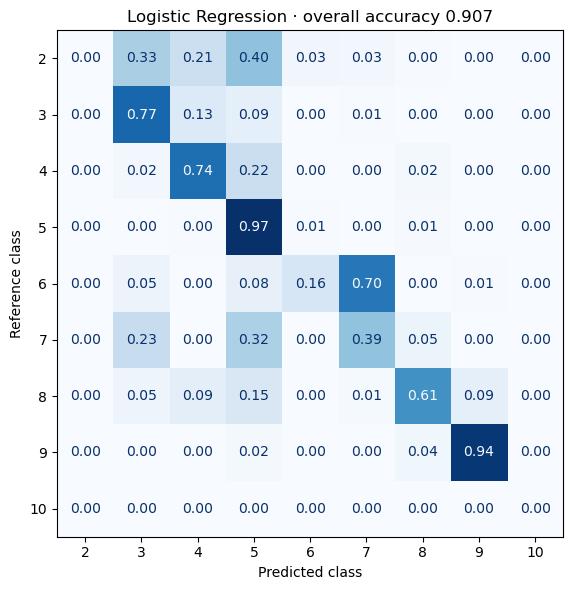

Logistic Regression: overall accuracy 0.9069
🏃 View run phase1-logistic_regression at: http://mlflow:5000/#/experiments/1/runs/803aff78a8874dc0aa29598bba24ef39
🧪 View experiment at: http://mlflow:5000/#/experiments/1


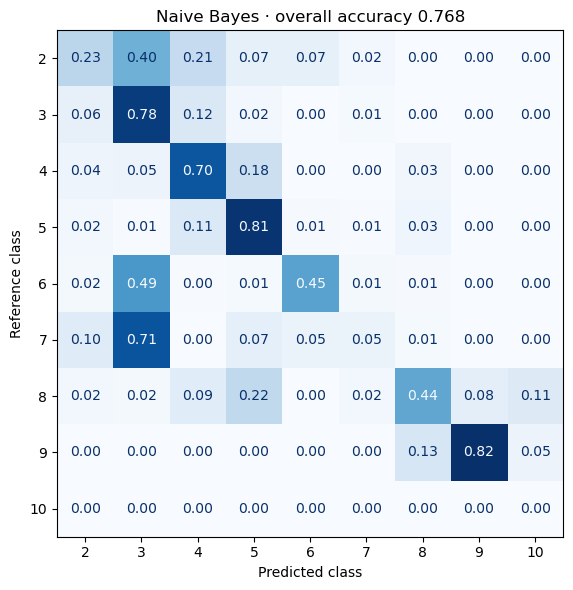

Naive Bayes: overall accuracy 0.7675
🏃 View run phase1-naive_bayes at: http://mlflow:5000/#/experiments/1/runs/9e11d2ccb5ec45d4a8a761b365aad28a
🧪 View experiment at: http://mlflow:5000/#/experiments/1


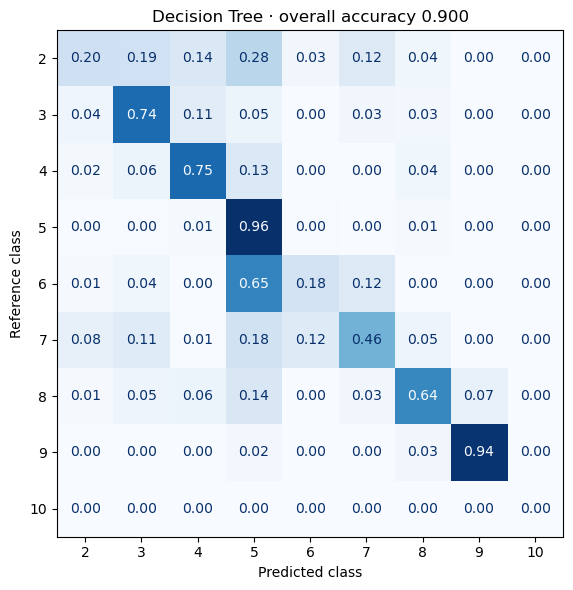

Decision Tree: overall accuracy 0.8996
🏃 View run phase1-decision_tree at: http://mlflow:5000/#/experiments/1/runs/0c7ca36fba8f4440aa7d93c84ca58fac
🧪 View experiment at: http://mlflow:5000/#/experiments/1


In [6]:
MODELS = {
    "logistic_regression": ("Logistic Regression", make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))),
    "naive_bayes": ("Naive Bayes", GaussianNB()),
    "decision_tree": ("Decision Tree", DecisionTreeClassifier(random_state=SEED)),
}
LABELS = sorted(y.unique())
# MLflow stores scikit-learn models with skops, which only loads the types listed as
# trusted; the fitted tree structure of the Decision Tree is not in its default list.
SKOPS_TRUSTED_TYPES = ["sklearn.tree._tree.Tree"]

mlflow.set_experiment(os.environ["MLFLOW_EXPERIMENT_NAME"])
results, matrices = [], {}
for key, (name, model) in MODELS.items():
    with mlflow.start_run(run_name=f"phase1-{key}") as run:
        model.fit(X_train, y_train)
        predicted = model.predict(X_test)

        metrics = {
            "overall_accuracy": accuracy_score(y_test, predicted),
            "kappa": cohen_kappa_score(y_test, predicted),
            "f1_macro": f1_score(y_test, predicted, labels=LABELS, average="macro", zero_division=0),
        }
        matrix = pd.DataFrame(confusion_matrix(y_test, predicted, labels=LABELS), index=LABELS, columns=LABELS)
        matrix.index.name, matrix.columns.name = "reference", "predicted"
        matrix.to_csv(OUTPUTS / f"confusion_matrix_{key}.csv")
        matrices[key] = matrix

        # Row-normalised: each cell is the share of the reference class.
        figure, axis = plt.subplots(figsize=(7, 6))
        ConfusionMatrixDisplay.from_predictions(
            y_test, predicted, labels=LABELS, normalize="true", values_format=".2f",
            cmap="Blues", colorbar=False, ax=axis,
        )
        axis.set(title=f"{name} · overall accuracy {metrics['overall_accuracy']:.3f}",
                 xlabel="Predicted class", ylabel="Reference class")
        figure.tight_layout()
        figure.savefig(OUTPUTS / f"confusion_matrix_{key}.png", dpi=150)
        plt.show()

        mlflow.log_params({
            "phase": 1, "model": name, "dataset": DATASET, "bands": ",".join(BANDS),
            "split": f"StratifiedGroupKFold by polygon, 1 of {TEST_FOLDS} folds held out", "seed": SEED,
            "train_samples": len(y_train), "test_samples": len(y_test),
        })
        mlflow.log_metrics(metrics)
        mlflow.log_artifact(OUTPUTS / f"confusion_matrix_{key}.png")
        mlflow.log_artifact(OUTPUTS / f"confusion_matrix_{key}.csv")
        mlflow.sklearn.log_model(model, name="model", skops_trusted_types=SKOPS_TRUSTED_TYPES)
        results.append({"key": key, "model": name, **metrics, "mlflow_run_id": run.info.run_id})
        print(f"{name}: overall accuracy {metrics['overall_accuracy']:.4f}")

## 4. Summary

The majority-class baseline is the accuracy of always predicting the most frequent class of the training set; a model is only useful above it.

In [7]:
majority_class = y_train.value_counts().idxmax()
baseline = float((y_test == majority_class).mean())

summary = pd.DataFrame(results).sort_values("overall_accuracy", ascending=False).reset_index(drop=True)
summary.drop(columns="key").to_csv(OUTPUTS / "summary.csv", index=False)
(OUTPUTS / "metrics.json").write_text(json.dumps({
    "dataset": DATASET, "samples": len(y), "polygons": int(groups.nunique()),
    "train_samples": len(y_train), "test_samples": len(y_test),
    "majority_class": int(majority_class), "majority_baseline_accuracy": baseline,
    "models": results,
}, indent=2))
print(f"majority-class baseline (class {majority_class}): {baseline:.4f}")
summary.drop(columns=["key", "mlflow_run_id"]).round(4)

majority-class baseline (class 5): 0.7411


,model,overall_accuracy,kappa,f1_macro
0,Logistic Regression,0.9069,0.7804,0.5156
1,Decision Tree,0.8996,0.7695,0.5393
2,Naive Bayes,0.7675,0.5494,0.4320


In [8]:
# Recall of every class (diagonal over the reference total): what the overall accuracy hides.
recall = pd.DataFrame({
    MODELS[key][0]: (matrix.values.diagonal() / matrix.sum(axis=1).where(lambda total: total > 0)).round(3)
    for key, matrix in matrices.items()
})
recall.insert(0, "test_samples", y_test.value_counts().reindex(LABELS, fill_value=0))
recall.insert(0, "name", recall.index.map(CLASS_NAMES))
recall.index.name = "Class"
recall.to_csv(OUTPUTS / "recall_per_class.csv")
recall

,name,test_samples,Logistic Regression,Naive Bayes,Decision Tree
Class,,,,,
2,Dark area pixels,819,0.000,0.232,0.201
3,Cloud shadows,6543,0.772,0.783,0.740
4,Vegetation,9270,0.741,0.703,0.749
5,Not vegetated,85109,0.974,0.807,0.961
6,Water,876,0.159,0.454,0.176
7,Unclassified,1302,0.395,0.055,0.459
8,Cloud medium probability,4837,0.609,0.439,0.637
9,Cloud high probability,6090,0.944,0.823,0.945
10,Thin cirrus,0,NaN,NaN,NaN
